<a href="https://colab.research.google.com/github/gitmystuff/INFO5810/blob/main/Module_12-Do_Calculus/Module12_Pearls_Ladder_and_Do_Calculus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 12: Pearl's Ladder of Causation and Do-Calculus

Your Name

## Getting Started

* Colab - get notebook from gitmystuff INFO5810 repository
* Save a Copy in Drive
* Remove Copy of
* Edit your name in the cell above and the filename
* Clean up Colab Notebooks folder
* Submit shared link

**INFO 5810 – Data Analysis and Knowledge Discovery**

**What you will be able to do after this module**
- Explain the three rungs of Pearl's Ladder (seeing, doing, imagining) and say which rung a question lives on.
- Explain what the do-operator means and why *forcing* a variable is different from *seeing* it.
- Explain why a causal effect must be **identified** (from a graph) before it can be **estimated** (from data).
- Estimate a causal effect several ways (comparing within groups, propensity score matching, inverse probability weighting, double machine learning) and check each against a known truth.
- Run the DoWhy workflow: model, identify, estimate, refute.
- Recognize two quiet mistakes that give wrong answers without any error message.

**Where this fits.** Module 11 asked: *can an algorithm find the arrows?* This module asks: *once we have a graph, how do we use it to answer "what if we did X?"* We stay with the same fraud story all the way through. Module 13 will climb to the third rung (counterfactuals and recourse).

## Part 0: Where we have been (quick recap)

| Module | What we did | Why it matters today |
|---|---|---|
| 9 | Built a **Bayesian network** for fraud risk: nodes (variables), arrows (influence), and a probability table (**CPT**) for each node. | The same fraud network is our story all module long. |
| 10 | Used **Bayes' theorem** to update beliefs when we *see* evidence. The numerator is a **joint probability**, built by multiplying CPT entries. | "Seeing" is rung 1 of the ladder. |
| 11 | Learned that **correlation is not causation**, drew **DAGs**, and used the **PC** and **GES** algorithms to find arrows. Hidden common causes (**latent confounders**) are the hardest case. The shark-bites and ice-cream story: both rise in summer because of a hidden third thing, **hot weather**. | A confounder is exactly what stops "seeing" from answering "doing." |

**Vocabulary check**
- **DAG**: a graph of arrows with no loops. An arrow means "directly influences."
- **Fork** (A ← C → B): C causes both, so A and B are correlated without either causing the other.
- **Collider** (A → C ← B): two causes of the same effect.
- **d-separation**: a rule for reading from the graph which variables are independent once you condition on others.
- **Confounder**: a common cause of both the "treatment" and the "outcome."

### Setup
In Google Colab the first cell below installs what we need. On a machine that already has the packages it does nothing.

In [ ]:
try:
    import dowhy, pgmpy
except ImportError:
    %pip install -q dowhy pgmpy

In [ ]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination, CausalInference

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.model_selection import KFold

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Ready.")

Ready.


### Rebuilding our fraud network from Modules 9–11
Five nodes, five CPTs. *PriorClaims* and *SuspiciousTiming* feed into *FraudRisk*, and *FraudRisk* produces two clues: *MismatchedReceipts* and *WitnessInconsistency*.

```
PriorClaims ─────┐
                 ├──► FraudRisk ──► MismatchedReceipts
SuspiciousTiming ┘          └─────► WitnessInconsistency
```
Remember: each CPT lists a probability for every combination of its **parents**. The first table (`FRAUD_CPT`) is the biggest because FraudRisk has two parents. Its columns are, in order, (PriorClaims, SuspiciousTiming) = (Yes, Yes), (Yes, No), (No, Yes), (No, No). For example, the first column says 90% of claims with both warning signs are high risk, and the last says only 3% of claims with neither are.

In [ ]:
edges = [("PriorClaims", "FraudRisk"), ("SuspiciousTiming", "FraudRisk"),
         ("FraudRisk", "MismatchedReceipts"), ("FraudRisk", "WitnessInconsistency")]

FRAUD_CPT = [[0.90, 0.55, 0.50, 0.03],     # P(FraudRisk = High | parents)
             [0.10, 0.45, 0.50, 0.97]]     # P(FraudRisk = Low  | parents)

cpd_prior   = TabularCPD("PriorClaims", 2, [[0.15], [0.85]],
                         state_names={"PriorClaims": ["Yes", "No"]})
cpd_timing  = TabularCPD("SuspiciousTiming", 2, [[0.10], [0.90]],
                         state_names={"SuspiciousTiming": ["Yes", "No"]})
cpd_fraud   = TabularCPD("FraudRisk", 2, FRAUD_CPT,
                         evidence=["PriorClaims", "SuspiciousTiming"], evidence_card=[2, 2],
                         state_names={"FraudRisk": ["High", "Low"],
                                      "PriorClaims": ["Yes", "No"],
                                      "SuspiciousTiming": ["Yes", "No"]})
cpd_receipts = TabularCPD("MismatchedReceipts", 2, [[0.75, 0.05], [0.25, 0.95]],
                          evidence=["FraudRisk"], evidence_card=[2],
                          state_names={"MismatchedReceipts": ["Yes", "No"], "FraudRisk": ["High", "Low"]})
cpd_witness = TabularCPD("WitnessInconsistency", 2, [[0.65, 0.04], [0.35, 0.96]],
                         evidence=["FraudRisk"], evidence_card=[2],
                         state_names={"WitnessInconsistency": ["Yes", "No"], "FraudRisk": ["High", "Low"]})

true_model = DiscreteBayesianNetwork(edges)
true_model.add_cpds(cpd_prior, cpd_timing, cpd_fraud, cpd_receipts, cpd_witness)
assert true_model.check_model()
infer = VariableElimination(true_model)
print("Fraud network rebuilt and checked.")

Fraud network rebuilt and checked.


Each number in `FRAUD_CPT` answers one question: **given this combination of the two parents, how likely is FraudRisk to be High (top row) or Low (bottom row)?**

**How to read the grid**

The two rows are the two states of FraudRisk, and the four columns are the four combinations of its two parents. The columns run in this order, with the last parent listed (SuspiciousTiming) changing fastest:

| Column | PriorClaims | SuspiciousTiming | P(High) | P(Low) | In plain words |
|---|---|---|---|---|---|
| 1 | Yes | Yes | **0.90** | 0.10 | Prior claims *and* suspicious timing: 9 in 10 are high risk. |
| 2 | Yes | No | **0.55** | 0.45 | Prior claims only: a bit better than a coin flip. |
| 3 | No | Yes | **0.50** | 0.50 | Suspicious timing only: a coin flip. |
| 4 | No | No | **0.03** | 0.97 | Neither warning sign: only 3 in 100 are high risk. |

So **0.90** means: among claims with prior claims and suspicious timing, 90% are high fraud risk. In notation, P(FraudRisk = High | PriorClaims = Yes, SuspiciousTiming = Yes) = 0.90.

**Three things to notice**

- **Each column adds to 1.0** (0.90 + 0.10, 0.55 + 0.45, and so on). Once you fix the parents, FraudRisk must be either High or Low, so the two probabilities share 100%.
- **The rows do not add to 1.** The top row (0.90, 0.55, 0.50, 0.03) is four separate answers to four separate questions, not one split of 100%.
- **The numbers tell a story.** Either warning sign alone puts a claim near 50%, both together push it to 90%, and neither leaves it at 3%. That is the "risk goes up with each warning sign" logic we want the network to carry.

**Where the numbers come from.** In this course they are invented for teaching. In a real company they would come from historical claims. For each of the four combinations you count how many past claims fell into it and what share were later confirmed as high risk. For example, 0.90 means 90% of past claims with both warning signs were confirmed.

**The `edges` list**

```python
edges = [("PriorClaims", "FraudRisk"), ("SuspiciousTiming", "FraudRisk"),
         ("FraudRisk", "MismatchedReceipts"), ("FraudRisk", "WitnessInconsistency")]
```
Each pair is an arrow, read as `(cause, effect)`:
- PriorClaims → FraudRisk
- SuspiciousTiming → FraudRisk
- FraudRisk → MismatchedReceipts
- FraudRisk → WitnessInconsistency

The edges say *who influences whom*. The CPT numbers say *how strongly*. The two parents of FraudRisk are why `FRAUD_CPT` has four columns, one per parent combination.

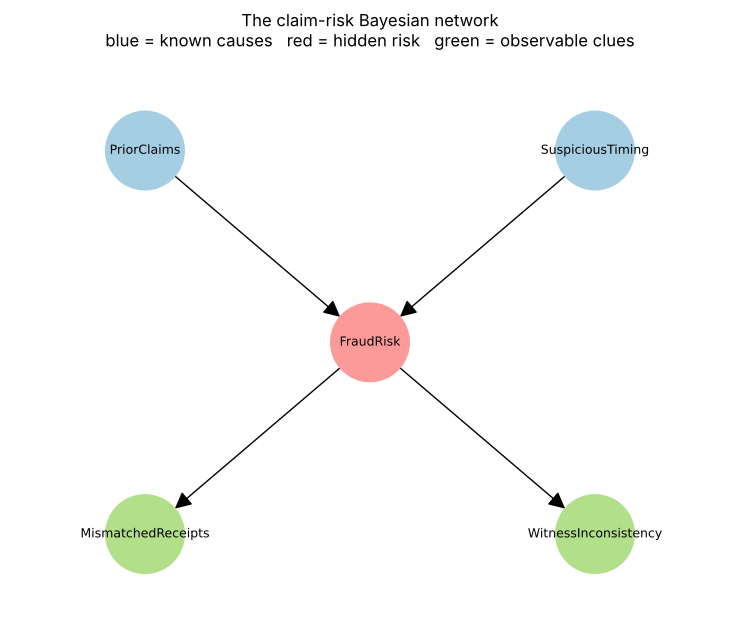

In [ ]:

# the DAG structure -- who influences whom (no probabilities yet, just edges)
edges = [
    ("PriorClaims", "FraudRisk"),
    ("SuspiciousTiming", "FraudRisk"),
    ("FraudRisk", "MismatchedReceipts"),
    ("FraudRisk", "WitnessInconsistency"),
]

G = nx.DiGraph(edges)

pos = {
    "PriorClaims": (-1, 1),
    "SuspiciousTiming": (1, 1),
    "FraudRisk": (0, 0),
    "MismatchedReceipts": (-1, -1),
    "WitnessInconsistency": (1, -1),
}

color_by_node = {
    "PriorClaims": "#a6cee3",
    "SuspiciousTiming": "#a6cee3",
    "FraudRisk": "#fb9a99",
    "MismatchedReceipts": "#b2df8a",
    "WitnessInconsistency": "#b2df8a",
}
# build the color list in G's own node order -- NEVER assume it matches the
# order nodes were typed in a dict or list above; a DiGraph built from an
# edge list orders nodes by first appearance across edges, which is easy
# to get subtly wrong (we did, the first time we wrote this cell)
node_colors = [color_by_node[n] for n in G.nodes()]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
nx.draw_networkx_nodes(G, pos, node_size=3200, node_color=node_colors, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(G, pos, arrowsize=25, arrowstyle="-|>", node_size=3200,
                        connectionstyle="arc3,rad=0.0", ax=ax)
ax.set_title("The claim-risk Bayesian network\nblue = known causes   red = hidden risk   green = observable clues")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.5, 1.5)
ax.axis("off")
plt.tight_layout()
plt.show()


## Part 1: Pearl's Ladder of Causation

### Meet Judea Pearl
**Judea Pearl** is a computer scientist at UCLA. In the 1980s he developed the **Bayesian network**, the tool we built in Module 9 and used for Bayes' theorem in Module 10. In 2011 he received the Turing Award, computing's highest honor, for his work on probabilistic and causal reasoning.

Then he spent decades on a harder problem: **cause and effect.** Together with science writer Dana Mackenzie he wrote *The Book of Why* (2018), which introduced an idea to frame answering cause and effect: **the Ladder of Causation.**

Here is the twist that matters for us. The person who gave us Bayesian networks is also the person who warned that a network used only for *looking* at data cannot answer *"what if?"* This module addresses this.

### The question we have been asking all along
Since Module 9 we have asked one question about fraud: **how likely is it that this claim is high risk, given what we see?** We answered it with a Bayesian network, and the answer was a probability.

But a business does not only want to *describe* claims. It wants to *act*. Two questions a manager might ask next:

1. *"If our investigators contacted claimants earlier, would we pay less money on average?"*
2. *"That claim paid $40,000. Would it have paid less if we had contacted the claimant sooner?"*

These are not the same kind of question as "how likely is fraud given a mismatched receipt?" And they cannot be answered with the same kind of evidence. (The first is an open question. Later in this module we practice answering it on simulated data, so we can check our work.) Pearl's ladder sorts questions like these into three levels.

### A ladder with three rungs

To understand cause and effect, you have to climb three rungs. Each rung asks a different *kind* of question, and each needs something the rung below does not have. Collecting more of the same data never gets you up a rung. What lifts you is adding something new: first a causal graph, then equations for how each variable is produced.

#### Rung 1: Seeing (association)
> *"What does what I observe tell me? What's the data telling me?"*

On rung 1 we **observe, and compare against data aggregates.** We look at the world as it is and ask which things go together. Notation: **P(y | x)**, "the probability of y given that we *see* x."

- **Smoking:** *Smokers get lung cancer more often than non-smokers.*
- **Fraud:** *Among claims with mismatched receipts, how often is fraud risk high?*

A rung 1 question can even be about one claim. In Module 9 we looked at a single claim and its clues. But notice how we answered it: by **comparing that claim against patterns in all the other claims.** The answer comes from the aggregate.

**What you need:** data. **Tools you already know:** correlation and regression, Bayes' theorem and the Bayesian networks from Modules 9–10, anomaly detection, clustering, and almost all of machine learning, from decision trees to deep learning. They differ in power, but they all do the same job: finding patterns in data as it is.

#### Rung 2: Doing (intervention)
> *"What happens if we change something?"*

Rung 2 is a **what if**: we do not just watch, we *act*, and ask what happens, again for a whole group. This is the idea of an **intervention (~RCT).** Notation: **P(y | do(x))**, "the probability of y if we *make* x happen."

The experimental way to answer a rung 2 question is a **randomized controlled trial (RCT)**: flip a coin to decide who gets the treatment, then compare. When we cannot run an experiment, there is another way: a **hypothesized causal graph**, our written-down assumptions about what causes what, combined with data. That second route is what do-calculus gives us.

- **Smoking:** *If we got a population to stop smoking, how much would cancer rates fall?*
- **Fraud:** *If we contacted every claimant early, what would happen to payouts? If we made every receipt match, what would happen to fraud?*

**What you need:** data **and** a causal graph (or an experiment). **Tools:** the do-operator and do-calculus (Parts 3 and 4).

#### Rung 3: Imagining (counterfactuals)
> *"Why did this happen to this case, and what would have happened if it had been different?"*

Rungs 1 and 2 are about groups. Rung 3 is about **one individual**: a single point in the huge space of everything that could be true about one case, including factors we never measured. We ask why *this particular* thing happened.

- **Smoking:** *This woman smoked for 30 years and developed cancer. Would she still have developed cancer if she had never smoked or stopped earlier in her life?*
- **Fraud:** *Claim C-1043 was not contacted and paid $40,000. Would it have paid less if we had contacted the claimant early?*

**What you need:** data, a graph, **and equations** describing how each variable is produced. **Tools:** structural causal models, in Module 13. We only open the door in Part 7.

#### The three rungs side by side

| | Rung 1: Seeing | Rung 2: Doing | Rung 3: Imagining |
|---|---|---|---|
| **Question** | What does X tell me about Y? | What happens to Y if we *make* X happen? | Why did this happen here, and what if it had been different? |
| **About** | Patterns in groups | Effects on groups | One specific case |
| **Notation** | P(y \| x) | P(y \| do(x)) | "y would have been different had x been different" |
| **You need** | Data | Data + graph (or an RCT) | Data + graph + equations |
| **Fraud example** | Mismatched receipt → how risky? | Contact everyone early → payouts? | Would *this* claim have paid less? |

> **The ladder sorts questions by what you need in order to answer them.**


### Seeing versus doing, in our own fraud network

Here is the difference in numbers, using the network we already built.

Suppose a team notices that claims with **mismatched receipts** tend to be high fraud risk. They reason: *"Mismatched receipts must be driving the fraud. If we fix the receipts (say, by requiring digital receipts and auditing them), fraud will drop."* Before spending the money, we can test that reasoning on our network with two different questions.

**Seeing (rung 1):** Among claims where we *observe* matching receipts, how likely is high fraud risk? We are only looking at the world as it is.

In [ ]:
# SEEING: among claims whose receipts we observe to match
seen = infer.query(["FraudRisk"], evidence={"MismatchedReceipts": "No"}, show_progress=False)
p_seen = seen.get_value(FraudRisk="High")

# DOING: make every claim's receipts match.
# Graph surgery: cut the arrow FraudRisk -> MismatchedReceipts,
# then fix MismatchedReceipts at "No" (matching receipts for everyone).
cut_model = DiscreteBayesianNetwork([e for e in edges if e[1] != "MismatchedReceipts"])
cut_model.add_node("MismatchedReceipts")
cpd_forced = TabularCPD("MismatchedReceipts", 2, [[0.0], [1.0]],
                        state_names={"MismatchedReceipts": ["Yes", "No"]})
cut_model.add_cpds(cpd_prior, cpd_timing, cpd_fraud, cpd_forced, cpd_witness)
assert cut_model.check_model()

done = VariableElimination(cut_model).query(["FraudRisk"], show_progress=False)
p_done = done.get_value(FraudRisk="High")

base = infer.query(["FraudRisk"], show_progress=False).get_value(FraudRisk="High")
print(f"Base rate P(FraudRisk = High)                       = {base:.4f}")
print(f"SEEING   P(High | we observe receipts match)        = {p_seen:.4f}")
print(f"DOING    P(High | do(receipts match for everyone))  = {p_done:.4f}")

Base rate P(FraudRisk = High)                       = 0.1532
SEEING   P(High | we observe receipts match)        = 0.0454
DOING    P(High | do(receipts match for everyone))  = 0.1532


Same variables, two very different answers:

- **Seeing: 0.0454.** Claims whose receipts happen to match are rarely high risk. That is a strong clue, because fraud tends to produce mismatched receipts.
- **Doing: 0.1532.** When we *make* receipts match for everyone, fraud risk stays exactly at its ordinary base rate.

Why? In the graph, the arrow runs **FraudRisk → MismatchedReceipts**. Fraud causes the receipt problem, not the other way around. Clean receipts are a *symptom* that fraud is absent, not a *cause* of it. When we force the receipts to match, we cut the arrow into that node, so nothing flows back to FraudRisk.

**The lesson.** The team saw a rung 1 pattern (matching receipts go with low fraud) and used it to answer a rung 2 question (will fixing receipts reduce fraud?).

**This is where the graph earns its place.** The data alone cannot tell us which way the influence runs: do bad receipts cause fraud, or does fraud cause bad receipts? Both stories produce the same pattern. The graph settles it by stating the direction: **FraudRisk → MismatchedReceipts**. Fraud produces the receipt problem, not the other way around. With that arrow in hand, we can answer the rung 2 question without running an expensive experiment: fixing the receipts leaves fraud where it was. The company would spend money on receipt audits and the fraud rate would not move. The same trap applies to witness statements, since both are symptoms of fraud risk (a fork, like the sharks and ice cream).

**There is a second cost.** Receipts are a useful clue today only because fraud makes them mismatch. If we force them to match for everyone, that connection is cut, and receipts stop telling investigators anything about fraud. We would have spent money and *lost a warning sign*.

So fixing a clue does not fix the cause. If we want to reduce what the company pays on risky claims, we need a lever that actually acts on the claims. That is the question we turn to in Part 2.

## Part 2: From clues to decisions: a lever the company can pull

So far every variable in our network is either a **risk factor** (PriorClaims, SuspiciousTiming) or a **clue** (receipts, witnesses). Nothing in it is a **decision** the company can make. To ask a rung 2 question about a real action, we add one.

**The decision: contact the claimant early.** Within 48 hours of filing, an investigator calls the claimant. The business question from Part 1: *if we contacted claimants early, would we pay less?*

**Why early contact might lower payouts (assumption for our story):** an early, friendly call makes a claimant less likely to hire an attorney, and attorneys tend to raise payouts. So early contact would reach the payout **through** the attorney. The attorney is a **mediator**: it sits *between* the action and the result.

**How the same fraud story connects**
- Every claim carries the **FraudRisk rating** (High or Low) from our network. Assume it is recorded in the claims file.
- Investigators can see the rating, so they call **high-risk claims first**. They also give extra attention to claimants with **prior claims** and **suspicious timing**. Early contact was never handed out at random. People chose.
- High-risk claims tend to **pay more** and are **more likely to involve an attorney**.

So **FraudRisk is a confounder**: it influences both who gets contacted and what gets paid. It plays the same role hot weather played for the sharks and the ice cream.

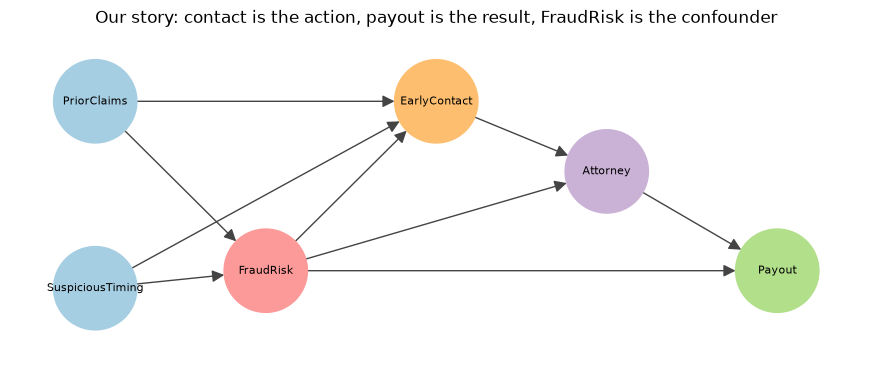

(Receipts and witnesses are still in the network. We leave them out here because we do not need them.)


In [ ]:
scenario = nx.DiGraph([
    ("PriorClaims", "FraudRisk"), ("SuspiciousTiming", "FraudRisk"),
    ("FraudRisk", "EarlyContact"), ("PriorClaims", "EarlyContact"), ("SuspiciousTiming", "EarlyContact"),
    ("FraudRisk", "Attorney"), ("EarlyContact", "Attorney"),
    ("Attorney", "Payout"), ("FraudRisk", "Payout")])

pos = {"PriorClaims": (0, 1.6), "SuspiciousTiming": (0, 0), "FraudRisk": (2, 0.15),
       "EarlyContact": (4, 1.6), "Attorney": (6, 1.0), "Payout": (8, 0.15)}
colors = {"PriorClaims": "#a6cee3", "SuspiciousTiming": "#a6cee3", "FraudRisk": "#fb9a99",
          "EarlyContact": "#fdbf6f", "Attorney": "#cab2d6", "Payout": "#b2df8a"}

fig, ax = plt.subplots(figsize=(11, 4.4))
nx.draw(scenario, pos, ax=ax, with_labels=True, node_size=3600, font_size=8,
        node_color=[colors[n] for n in scenario.nodes], arrowsize=18, edge_color="#444")
ax.set_xlim(-1, 9); ax.set_ylim(-0.7, 2.2)
ax.set_title("Our story: contact is the action, payout is the result, FraudRisk is the confounder")
plt.show()
print("(Receipts and witnesses are still in the network. We leave them out here because we do not need them.)")

Read the picture from left to right:
- **Red (FraudRisk)** has arrows into the action (EarlyContact) *and* into the result (Payout). That is the confounding.
- **Orange (EarlyContact)** is the action we are considering.
- **Purple (Attorney)** is the mediator, the route by which early contact is supposed to work.
- **Green (Payout)** is what we want to change.

**A note on the data.** We want to practice on data where we *secretly know the true effect of early contact*, so we can grade our methods. Real data never tells you the answer, so we **simulate** a year of past claims. The simulation uses the same probabilities as our fraud network for PriorClaims, SuspiciousTiming and FraudRisk, then adds contact, attorney and payout using rules we chose for teaching.

In [ ]:
def simulate(n=12000, seed=12):
    rng = np.random.default_rng(seed)

    # --- Same story as the fraud network (Modules 9-11) ---
    prior = rng.binomial(1, 0.15, n)                       # P(PriorClaims = Yes) = 0.15
    timing = rng.binomial(1, 0.10, n)                      # P(SuspiciousTiming = Yes) = 0.10
    p_high = np.where(prior == 1,
                      np.where(timing == 1, FRAUD_CPT[0][0], FRAUD_CPT[0][1]),
                      np.where(timing == 1, FRAUD_CPT[0][2], FRAUD_CPT[0][3]))
    high = rng.binomial(1, p_high)                         # 1 = FraudRisk High

    # --- New: investigators choose who to contact early (not random!) ---
    p_contact = 1 / (1 + np.exp(-(-2.0 + 2.6 * high + 0.7 * prior + 0.5 * timing)))
    contact = rng.binomial(1, p_contact)

    # --- New: attorney (less likely after early contact) and payout ---
    u = rng.uniform(size=n)
    def attorney_if(c):
        p = 1 / (1 + np.exp(-(-1.3 + 1.6 * high - 1.0 * c)))
        return (u < p).astype(int)
    a0, a1 = attorney_if(0), attorney_if(1)
    noise = rng.normal(0, 1200, n)
    def payout_if(a):
        return 9000 + 6000 * high + 4000 * a + noise
    y0, y1 = payout_if(a0), payout_if(a1)                  # payout if NOT contacted / if contacted

    return pd.DataFrame({
        "PriorClaims": prior, "SuspiciousTiming": timing, "FraudHigh": high,
        "EarlyContact": contact,
        "Attorney": np.where(contact == 1, a1, a0),
        "Payout": np.where(contact == 1, y1, y0),
        "Y0": y0, "Y1": y1})                               # the 'locked drawer' columns

full = simulate()
observed = full[["PriorClaims", "SuspiciousTiming", "FraudHigh", "EarlyContact", "Attorney", "Payout"]]
locked_drawer = full[["Y0", "Y1"]]
observed.head()

,PriorClaims,SuspiciousTiming,FraudHigh,EarlyContact,Attorney,Payout
0,0,0,0,0,0,"8,423.6722"
1,1,1,1,1,0,"13,798.3447"
2,0,1,0,0,0,"10,003.0110"
3,0,0,0,1,0,"10,607.4390"
4,0,1,1,1,0,"12,453.7367"


Two tables now exist.

- `observed` is what a real analyst gets: last year's claims, with **one** payout per claim, from whichever world actually happened. `FraudHigh = 1` means the claim was rated High risk. `EarlyContact` is already a column, because investigators contacted some claimants and not others, using their own judgment. **Nobody ran an experiment.** The data only record what happened.
- `locked_drawer` holds each claim's payout in **both** worlds (contacted and not contacted). In real life the drawer does not exist. Here we built it so we can grade our methods later. **We will not open the drawer until Part 4.**

### The tempting (wrong) comparison

**The question.** Does contacting a claimant early change the payout? The policy we are weighing is *"contact everyone early,"* which has never been tried. It is the intervention, `do(EarlyContact = 1)`.

**Why we can't just look.** To answer for one claim, we would compare two worlds: the claim *with* early contact and the same claim *without* it. But every claim lives in only one world. A contacted claim never shows us what it would have paid without contact.

**So we borrow.** We use the claims that were *not* contacted as stand-ins for what the contacted claims would have looked like without contact. That is why we compare two groups.

**A stand-in only works if it resembles the original.** Imagine testing a fertilizer by putting it on one tomato garden and leaving another plain. If the gardens have the same soil and sun, a bigger harvest is probably the fertilizer. If the fertilizer went on the sunny, rich-soil garden, the bigger harvest could be the sun and soil. We want the groups to differ in only one thing: whether they were contacted.

**Do our groups resemble each other?** Let's see.

In [ ]:
g = observed.groupby("EarlyContact")[["FraudHigh", "Attorney", "Payout"]].mean()
g.columns = ["Share rated High risk", "Share with attorney", "Average payout"]
print(g)

naive = g.loc[1, "Average payout"] - g.loc[0, "Average payout"]
print("Naive difference in average payout (contacted minus not): ${:,.0f}".format(naive))

              Share rated High risk  Share with attorney  Average payout
EarlyContact                                                            
0                            0.0443               0.2339     10,195.0497
1                            0.5079               0.2021     12,860.7727
Naive difference in average payout (contacted minus not): $2,666


**What you expected is the truth.** Early contact *should* lower payouts, and in our simulation it does: the true effect is about **−$581** per claim. That is the number we are trying to recover.

**The table shows the misleading answer.** It is the naive comparison, which says contacted claims paid about $2,666 *more*. It looks backwards because it is wrong in the way confounding makes things wrong. Look at the first column:

| Group | Claims rated High fraud risk | Average payout |
|:---|---:|---:|
| Not contacted | 4.4\% | \$10,195 |
| Contacted early | 50.8\% | \$12,861 |

The contacted group is about half high fraud risk, because investigators called those claims first. Claims rated High pay much more on their own (about $6,000 more in our story). So the contacted group's payouts are higher because it contains more expensive claims, not because the call raised them. The early call's small saving is buried under that difference.

**It is the same trap as the sharks and ice cream.** Ice cream sales and shark bites rise together, but ice cream does not cause bites. Here, early contact and high payouts rise together, but contact is not raising the payouts.

**Where the true answer appears.** When we compare within the same rating (Part 4.2), contacted claims pay *less* in both groups: about −\$1,040 for High and −\$510 for Low. That matches what you expected.


## Part 3: Rung 2 and do-calculus



### 3.1 What is a "calculus"?
Despite the name, a **calculus** here does not mean derivatives and integrals. A *calculus* is simply **a set of rules for rewriting expressions**, so that you can start with one expression and transform it step by step into another, always safely.

Algebra is a calculus: "you may add the same number to both sides." Starting with 3x + 5 = 20, subtract 5 from both sides to get 3x = 15, then divide by 3 to get x = 5. Each rule is safe because it never changes what the expression means.

**Do-calculus** is a calculus for probabilities that contain `do(...)`. Its job: take a question about *forcing* something and, **if the graph allows it**, rewrite it into an expression that contains only *seeing*, which we can compute from data.



### 3.2 What does `do(X = x)` mean?
- **P(Y | X = x)**: among the cases where X happened to equal x, what is Y? *(We look at the world as it is.)*
- **P(Y | do(X = x))**: if we **set** X to x for everyone, regardless of what would have caused X, what is Y? *(We change the world.)*

Pearl's picture: `do(X = x)` is **graph surgery**. We **cut every arrow pointing into X**, because X is now decided by us, not by its usual causes, and then we set X to the chosen value.

Here is the surgery from Part 1, where we forced receipts to match:

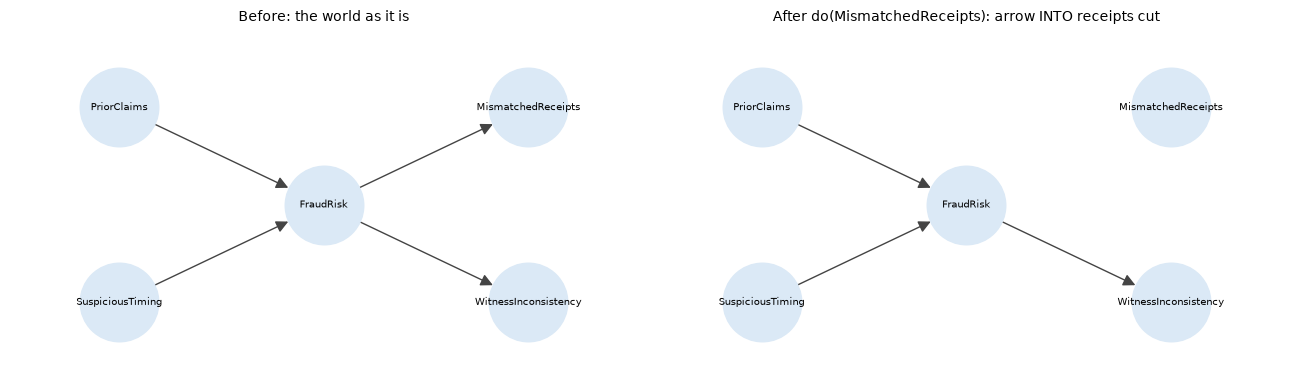

In [ ]:
def draw(G, title, ax, pos):
    nx.draw(G, pos, ax=ax, with_labels=True, node_size=3200, node_color="#dbe9f6",
            font_size=7, arrowsize=18, edge_color="#444")
    ax.set_xlim(-0.8, 3.8); ax.set_ylim(-0.4, 1.4)
    ax.set_title(title, fontsize=10)

pos_f = {"PriorClaims": (0, 1), "SuspiciousTiming": (0, 0), "FraudRisk": (1.5, 0.5),
         "MismatchedReceipts": (3, 1), "WitnessInconsistency": (3, 0)}
G = nx.DiGraph(edges)
G_cut = G.copy()
G_cut.remove_edges_from(list(G_cut.in_edges("MismatchedReceipts")))    # the surgery

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
draw(G, "Before: the world as it is", ax[0], pos_f)
draw(G_cut, "After do(MismatchedReceipts): arrow INTO receipts cut", ax[1], pos_f)
plt.tight_layout(); plt.show()

In the right-hand picture the receipts node is disconnected from FraudRisk. Nothing flows backward from receipts to fraud, which is why forcing the receipts could not change fraud (0.1532 in Part 1).

### 3.3 The same idea as arithmetic: the truncated factorization
Recall from Modules 9–10 that the joint probability is a product of CPT entries, one factor per node. Graph surgery has a very simple arithmetic meaning: **drop the factor for the node you are forcing, and plug in the value you chose.**

Let's test it on a question with an answer we can check three ways: **if we make receipts match for every claim, how often are witness statements inconsistent?**

**Step by step (the "six-step worked example")**
1. **Seeing answer.** Observe matching receipts and ask about witnesses. Matching receipts are a *clue* that fraud is probably absent, and fraud shows up in witnesses too, so the answer is deflated.
2. **Doing question.** Force receipts to match. Cut the arrow FraudRisk → Receipts.
3. **Check the graph.** Is there an arrow from receipts to witnesses? **No.** Receipts and witnesses are siblings (both children of FraudRisk).
4. **Rewrite.** Without the factor for receipts, the only thing left that determines witnesses is FraudRisk, which keeps its *original* distribution: P(W = Yes | do(R = No)) = Σ over fraud of P(fraud) × P(W = Yes | fraud). This is the **adjustment formula**, adjusting for FraudRisk.
5. **Compute** it with the CPT numbers.
6. **Cross-check** with the library and with the cut network.

In [ ]:
# Step 1: SEEING
p_w_seen = infer.query(["WitnessInconsistency"], evidence={"MismatchedReceipts": "No"},
                       show_progress=False).get_value(WitnessInconsistency="Yes")

# Steps 4-5: the adjustment formula, written out by hand
p_fraud = infer.query(["FraudRisk"], show_progress=False)
p_w_given_fraud = {f: infer.query(["WitnessInconsistency"], evidence={"FraudRisk": f},
                                  show_progress=False).get_value(WitnessInconsistency="Yes")
                   for f in ["High", "Low"]}
p_w_adjust = sum(p_fraud.get_value(FraudRisk=f) * p_w_given_fraud[f] for f in ["High", "Low"])

# Step 6: library's do() query, and the cut network from Part 1
ci = CausalInference(true_model)
p_w_do = ci.query(variables=["WitnessInconsistency"], do={"MismatchedReceipts": "No"},
                  show_progress=False).get_value(WitnessInconsistency="Yes")
p_w_cut = VariableElimination(cut_model).query(["WitnessInconsistency"],
                  show_progress=False).get_value(WitnessInconsistency="Yes")
p_w_base = infer.query(["WitnessInconsistency"], show_progress=False).get_value(WitnessInconsistency="Yes")

print(f"Base rate  P(Witness inconsistent)                       = {p_w_base:.4f}")
print(f"Seeing     P(W = Yes | R = No)                           = {p_w_seen:.4f}")
print(f"By hand    sum_f P(f) * P(W = Yes | f)   [do(R = No)]    = {p_w_adjust:.4f}")
print(f"pgmpy do   P(W = Yes | do(R = No))                       = {p_w_do:.4f}")
print(f"Cut model  P(W = Yes) after the surgery                  = {p_w_cut:.4f}")

Base rate  P(Witness inconsistent)                       = 0.1335
Seeing     P(W = Yes | R = No)                           = 0.0677
By hand    sum_f P(f) * P(W = Yes | f)   [do(R = No)]    = 0.1335
pgmpy do   P(W = Yes | do(R = No))                       = 0.1335
Cut model  P(W = Yes) after the surgery                  = 0.1335


Read the results:
- **0.0677 (seeing)**: matching receipts make witness problems look much *less* likely, because both are symptoms of the same cause.
- **0.1335 (doing, three ways)**: when we *force* receipts to match, nothing changes for witnesses. The answer equals the **base rate**.

The by-hand formula, the library and the cut network all agree, and we got there using only (a) the graph and (b) ordinary probabilities. That is what do-calculus buys us. **The graph licensed the rewrite; the data filled in the numbers.**

### 3.4 The backdoor idea in plain words
When you want the effect of X on Y, **every path from X to Y that starts with an arrow *into* X is a "backdoor" path.** Those paths carry confounding. To get the causal effect from observational data, you must **block all backdoor paths** by adjusting for the right variables, a set that blocks them without opening new paths. The adjustment formula is

> $P(Y \mid \mathrm{do}(X=x)) = \sum_{z} P(Y \mid X, Z = z)\, P(Z = z)$

meaning: compare X within groups of identical Z, then average the groups by how common they are in the *whole* population.

**In the claims story.** The backdoor path from EarlyContact to Payout runs **EarlyContact ← FraudRisk → Payout** (and also **EarlyContact ← FraudRisk → Attorney → Payout**). Adjusting for **FraudRisk** blocks both. In plain words: *compare contacted and uncontacted claims within the same risk rating, then average the ratings by how common they are.*

**Which variable must we *not* adjust for?** The **attorney**. It sits *on* the causal path (EarlyContact → Attorney → Payout). Adjusting for it would block the very effect we want to measure. We will see this happen in Part 6.

Here is the explanation, piece by piece, using our claims example. The numbers come from the Part 4.2 output.

**The formula**

$$P(Y = y \mid \mathrm{do}(X = x)) = \sum_{z} P(Y = y \mid X = x, Z = z)\, P(Z = z)$$

**Read it in words:** *to find what happens to Y if we force X, compare within each group of Z, then average the groups by how common each group is in the whole population.*

**The pieces**

| Symbol | Meaning | In our claims story |
|:---|:---|:---|
| $Y$ | the outcome | Payout |
| $X$ | the action we force | EarlyContact |
| $Z$ | the confounder we adjust for | FraudRisk rating (High or Low) |
| $P(Y \mid X = x, Z = z)$ | what we see *inside one group* of Z | average payout for contacted claims within the rating |
| $P(Z = z)$ | how common that group is | share of all claims with that rating |
| $\sum_z$ | add up over every group | add the High and Low groups |

**Walk through it with the real numbers.** Our claims are 85% rated Low and 15% rated High, and within each rating we saw:

| Rating | Share of all claims | Contacted, average payout | Not contacted, average payout |
|:---|---:|---:|---:|
| Low | 0.85 | \$9,352 | \$9,866 |
| High | 0.15 | \$16,261 | \$17,296 |

If we **force everyone to be contacted**, the formula gives
$0.85 \times 9{,}352 + 0.15 \times 16{,}261 \approx \$10{,}388$.

If we **force no one to be contacted**:
$0.85 \times 9{,}866 + 0.15 \times 17{,}296 \approx \$10{,}980$.

The difference is $10{,}388 - 10{,}980 \approx -\$592$, so early contact lowers the average payout by about $592. That matches the true effect of −\$581 that we check in Part 4.

**Why weight by P(Z) from the whole population?** This is the heart of the formula, and it is easy to miss.

- Contacted claims are mostly High rated (about 51%), and uncontacted claims are mostly Low (about 96%). If we simply averaged each group as it is, the groups would contain different mixes of ratings, and the comparison would be unfair.
- The formula gives *both* worlds the **same mix**, the real-world mix of 85% Low and 15% High. Now the only difference between the two worlds is the contact.
- This is what `do` means here: we imagine setting contact for everyone, without changing who the claimants are.

**Where the graph comes in.** The formula only works if Z blocks every backdoor path from X to Y. In our graph, EarlyContact ← FraudRisk → Payout is the backdoor path, and adjusting for FraudRisk closes it. If a confounder is missing from Z, the formula gives the wrong answer. That is the "rating unrecorded" mistake in Part 6.

**One technical note.** The formula as written is for probabilities. For an average payout like ours, replace $P(Y = y \mid \dots)$ with the average $E[Y \mid \dots]$. The structure is identical.

### 3.5 The three rules of do-calculus

Do-calculus has three rules. Each one says: *"you may rewrite this expression in this way **if** a d-separation condition holds in a modified version of the graph."* (d-separation is from Module 11.)

1. **Ignore an observation.** You may drop a variable you merely *see* if it is independent of the outcome in the right graph. *(Irrelevant evidence can be deleted.)*
2. **Swap seeing for doing.** You may treat "I force Z" as the same as "I see Z" if Z has no open backdoor path to the outcome. *(This is the rule that turns the backdoor adjustment into probabilities we can compute from data.)*
3. **Ignore an action.** You may drop a `do(...)` if forcing that variable cannot affect the outcome in the right graph. *(Forcing something irrelevant changes nothing. We used this idea in Part 1: forcing receipts could not change fraud.)*

A backdoor path is a route in the graph that links the action to the outcome by entering the action from behind, through an arrow that points into it. It is a non-causal route, and it carries confounding.

You will not apply these by hand in this course. What you should remember: **they are a complete toolkit.** If a causal effect can be written in terms of observed data using the graph, these rules are enough to find the rewrite. If the rules cannot remove the `do`, then the graph and the data together cannot answer the question. (This completeness result is due to work by Shpitser and Pearl, and by Huang and Valtorta.) Software such as DoWhy runs the search for you.

### 3.6 Identification versus estimation: two different jobs
- **Identification** asks: *Can the causal effect be written as something computable from observed data, given the graph?* It is a **logic question** that uses the graph. It does not use any numbers.
- **Estimation** asks: *Given that it can, what number does our finite sample give?* It is a **statistics question**. It uses the data.

**Example.** In the claims story, identification says: "the effect of early contact equals the adjustment formula over FraudRisk." That is the answer to *what to compute*. Estimation is how we compute it: comparing within groups, matching, weighting, double machine learning. Different estimators, same identified target.

If identification fails (for example, a confounder is hidden and unmeasured) then **no estimator can rescue you**. Better statistics cannot make up for a missing variable.

### 3.7 A word about front-door adjustment
Sometimes the confounder is **hidden**, so backdoor adjustment is impossible. If there is a **mediator** that carries the full effect and is itself *shielded from the hidden confounder*, the **front-door** rule still identifies the effect: estimate treatment → mediator, then mediator → outcome (adjusting for the treatment), and chain the two. It is a clever trick that shows the do-calculus can find answers that look impossible. We only name it here; DoWhy checks for it automatically.

## Part 4: Estimating the effect

Part 3 told us **what** to compute. Identification said: *the effect of early contact equals the adjustment formula over the fraud risk rating.* That was logic about the graph. It did not produce a single number.

An **estimator** is the **how**: a recipe for turning that formula into a number using a real sample of claims. Think of identification as the question written correctly, and estimation as the arithmetic that answers it.

**Why we need several recipes.** With one confounder, the formula is easy: compare contacted and uncontacted claims within each rating, then average. Real claims files have dozens of confounders (age, region, type of loss, policy history). Comparing within every combination of them is impossible, because there are too many groups and most are empty. So statisticians built different ways to do the *same* adjustment when you cannot count the groups:

| Estimator | The idea in one line |
|:---|:---|
| **Compare within groups** | Compare inside each group, then average. The formula, directly. |
| **Propensity score matching (PSM)** | Pair each claim with look-alikes from the other group and borrow their payout. |
| **Inverse probability weighting (IPW)** | Reweight the data so the two groups look alike. |
| **Double machine learning (DML)** | Use machine learning to remove what the confounders explain, then measure what is left. |

**Every estimator does the same job: it fills in the missing half.** For each claim we only see one world. An estimator borrows from similar claims to estimate the other, and then averages the difference. The missing half is the same as answering what if something else happened. Remember, a decision is a choice between alternatives, and you cannot judge a choice without knowing what the other option would have produced.

**What an estimator cannot do.** It can only carry out the adjustment you tell it to. If the graph is wrong, or a confounder is missing from the data, every estimator will confidently give the wrong answer. Do-calculus decides *what* to adjust for. The estimator decides *how* to compute it.

To grade the estimators fairly, we will check each one against a known true answer.

### 4.1 The true answer, and why it is hidden in real life
Every claim has two potential payouts: one if contacted (**Y1**), one if not (**Y0**). The **individual effect** is Y1 − Y0. The **average treatment effect (ATE)** is the average of that over all claims.

The **fundamental problem of causal inference**: for each claim we only ever observe *one* of the two. A claim that was contacted shows us Y1, and its Y0 is forever missing. Causal methods are all ways of *filling in the missing half* by borrowing from similar claims.

Here, because we built the drawer, we can compute the true answer:

In [ ]:
TRUE_ATE = (locked_drawer["Y1"] - locked_drawer["Y0"]).mean()
print(f"TRUE average effect of early contact on payout: ${TRUE_ATE:,.0f}")
print(f"Naive comparison from observed data:            ${naive:,.0f}")

TRUE average effect of early contact on payout: $-581
Naive comparison from observed data:            $2,666


The **true effect is about −\$600**: early contact *saves* roughly \$600 per claim on average, by discouraging attorneys. The naive comparison said **about +\$2,700**, wrong in both size and sign. Now let's see which methods recover about −\$600 from the `observed` table alone.

All the methods rely on two assumptions:
- **No unmeasured confounding**: the recorded variables (FraudRisk, PriorClaims, SuspiciousTiming) capture all the common causes of contact and payout.
- **Overlap (positivity)**: for every kind of claim, both contacted and uncontacted examples exist.

### 4.2 The simplest estimator: compare within each risk rating
Our backdoor formula says: compare contacted and uncontacted claims **within the same FraudRisk rating**, then average the two ratings by how common they are.

In [ ]:
rows = []
for rating, grp in observed.groupby("FraudHigh"):
    c, u = grp[grp.EarlyContact == 1], grp[grp.EarlyContact == 0]
    rows.append({"Rating": "High" if rating == 1 else "Low", "Claims": len(grp),
                 "Share of all claims": len(grp) / len(observed),
                 "Contacted avg payout": c.Payout.mean(), "Not contacted avg payout": u.Payout.mean(),
                 "Difference": c.Payout.mean() - u.Payout.mean()})
within = pd.DataFrame(rows).set_index("Rating")
print(within.round(2))

ate_strat = (within["Difference"] * within["Share of all claims"]).sum()
print(f"Adjustment formula (weighted average of the differences): ${ate_strat:,.0f}   (truth ${TRUE_ATE:,.0f})")

        Claims  Share of all claims  Contacted avg payout  \
Rating                                                      
Low      10204               0.8500            9,351.9300   
High      1796               0.1500           16,260.6800   

        Not contacted avg payout  Difference  
Rating                                        
Low                   9,865.7000   -513.7700  
High                 17,296.4600 -1,035.7800  
Adjustment formula (weighted average of the differences): $-592   (truth $-581)


**This is the adjustment formula in action.** Inside each rating, contacted claims pay a little *less* than uncontacted ones. The big gap we saw earlier came from mixing ratings together. Averaging the within-rating differences by how common each rating is gives an answer close to the truth.

With a single confounder this is all we need. Real claims files have dozens of confounders, and comparing within every combination becomes impossible. That is where the next three tools come in. They are different ways of doing the same adjustment when there are too many groups to count.

### 4.3 The propensity score
The **propensity score** is each claim's probability of being contacted early, given its recorded characteristics: `e(x) = P(EarlyContact = 1 | x)`. Claims with the same propensity score were equally likely to land in either group, so comparing them is a fair fight. It compresses many confounders into one number.

In our data there are only eight kinds of claim (rating × prior claims × timing), so we can see the propensity directly:

In [ ]:
X = observed[["FraudHigh", "PriorClaims", "SuspiciousTiming"]]
t = observed["EarlyContact"].values
y = observed["Payout"].values

table = (observed.groupby(["FraudHigh", "PriorClaims", "SuspiciousTiming"])["EarlyContact"]
         .agg(Claims="size", Share_contacted="mean").reset_index())
table["FraudHigh"] = table["FraudHigh"].map({1: "High", 0: "Low"})
print(table)

ps_model = LogisticRegression(max_iter=1000).fit(X, t)
e = ps_model.predict_proba(X)[:, 1]
print("Propensity scores run from", e.min().round(3), "to", e.max().round(3))

  FraudHigh  PriorClaims  SuspiciousTiming  Claims  Share_contacted
0       Low            0                 0    8978           0.1220
1       Low            0                 1     466           0.1652
2       Low            1                 0     748           0.2246
3       Low            1                 1      12           0.1667
4      High            0                 0     237           0.6329
5      High            0                 1     525           0.7867
6      High            1                 0     867           0.7832
7      High            1                 1     167           0.8563
Propensity scores run from 0.122 to 0.862


Each row is one kind of claim. `Share_contacted` is its propensity: high-risk claims with prior claims and suspicious timing are contacted more than 8 times in 10, while low-risk claims with neither warning sign are contacted about 1 time in 8. Both groups appear in every row, so **overlap is fine**. Every kind of claim has some contacted and some uncontacted examples to compare.

### 4.4 Propensity score matching (PSM)
**Idea:** for every claim, find claims in the *other* group with the same propensity score, and borrow their average payout as the missing half. Then average the differences.

In [ ]:
def psm_ate(e, t, y):
    key = np.round(e, 6)                                  # claims with the same propensity share a key
    d = pd.DataFrame({"k": key, "t": t, "y": y})
    avg_treated = d[d.t == 1].groupby("k").y.mean()      # average payout of contacted claims per key
    avg_control = d[d.t == 0].groupby("k").y.mean()      # average payout of uncontacted claims per key
    y1 = np.where(t == 1, y, d.k.map(avg_treated))       # uncontacted claims borrow a contacted twin's payout
    y0 = np.where(t == 0, y, d.k.map(avg_control))       # contacted claims borrow an uncontacted twin's payout
    return np.mean(y1 - y0), d, avg_control

ate_psm, d_match, avg_control = psm_ate(e, t, y)
print(f"PSM estimate of the effect: ${ate_psm:,.0f}   (truth ${TRUE_ATE:,.0f})")

PSM estimate of the effect: $-594   (truth $-581)


**Did matching actually create a fair comparison?** Check **balance**: the share of high-risk claims should be similar in both groups *after* matching, which it was not at the start.

In [ ]:
fraud = observed["FraudHigh"].values
share_treated = fraud[t == 1].mean()
share_control_before = fraud[t == 0].mean()

# after matching: each contacted claim's matched controls are the uncontacted claims with its same propensity key
control_fraud_by_key = pd.Series(fraud[t == 0]).groupby(d_match.k[t == 0].values).mean()
share_control_after = d_match.k[t == 1].map(control_fraud_by_key).mean()

print(f"Share high-risk among contacted claims:                    {share_treated:.1%}")
print(f"Share high-risk among uncontacted claims, BEFORE matching: {share_control_before:.1%}")
print(f"Share high-risk among uncontacted claims, AFTER matching:  {share_control_after:.1%}")

Share high-risk among contacted claims:                    50.8%
Share high-risk among uncontacted claims, BEFORE matching: 4.4%
Share high-risk among uncontacted claims, AFTER matching:  50.8%


### 4.5 Inverse probability weighting (IPW)
**Idea:** instead of picking twins, **reweight** the data so the two groups look alike. A contacted claim that was *unlikely* to be contacted (low propensity) is rare and informative, so it counts for more: weight `1/e`. An uncontacted claim that was *unlikely to be uncontacted* counts for more: weight `1/(1−e)`. After weighting, it is as if contact had been handed out at random.

**The weakness:** if a propensity is very close to 0 or 1, the weight becomes enormous and a single claim can dominate the answer. This is the practical cost of weak overlap.

In [ ]:
e_clip = np.clip(e, 0.02, 0.98)                           # guard rail against extreme weights
w = np.where(t == 1, 1 / e_clip, 1 / (1 - e_clip))
ate_ipw = np.mean(t * y / e_clip - (1 - t) * y / (1 - e_clip))

print(f"IPW estimate of the effect: ${ate_ipw:,.0f}   (truth ${TRUE_ATE:,.0f})")
print(f"Largest weight: {w.max():.1f}   Typical weight: {np.median(w):.1f}")
print("Here the weights are modest because overlap is good. If one kind of claim were almost never")
print("contacted, its few contacted examples would get weights in the hundreds and could dominate.")

IPW estimate of the effect: $-586   (truth $-581)
Largest weight: 8.2   Typical weight: 1.1
Here the weights are modest because overlap is good. If one kind of claim were almost never
contacted, its few contacted examples would get weights in the hundreds and could dominate.


### 4.6 Double machine learning (DML)
PSM and IPW model the *treatment*. Regression models the *outcome*. **Double ML uses both, with flexible machine-learning models, and removes their mistakes from each other.** In plain words:

1. Use ML to predict **Payout** from the confounders. Keep the **leftover** (the residual): the part of payout the confounders *cannot* explain.
2. Use ML to predict **EarlyContact** from the same confounders. Keep its leftover too: the part of contact that was *not* explained by the confounders, and so behaves "as if random."
3. Regress the payout leftover on the contact leftover. The slope is the causal effect.

Predictions are **cross-fitted** (each claim is predicted by a model that never saw it), which stops the ML from memorizing noise.

In [ ]:
Xc = observed[["FraudHigh", "PriorClaims", "SuspiciousTiming"]].values
res_y, res_t = np.zeros(len(y)), np.zeros(len(y))

for train, test in KFold(5, shuffle=True, random_state=0).split(Xc):
    m_y = GradientBoostingRegressor(random_state=0).fit(Xc[train], y[train])
    m_t = GradientBoostingClassifier(random_state=0).fit(Xc[train], t[train])
    res_y[test] = y[test] - m_y.predict(Xc[test])
    res_t[test] = t[test] - m_t.predict_proba(Xc[test])[:, 1]

ate_dml = (res_t @ res_y) / (res_t @ res_t)
print(f"DML estimate of the effect: ${ate_dml:,.0f}   (truth ${TRUE_ATE:,.0f})")

DML estimate of the effect: $-630   (truth $-581)


Where does do-calculus fit in? **All of these estimators answer the same question: they fill in the identified formula.** Do-calculus told us *what* to adjust for (the FraudRisk rating, and harmlessly the other recorded risk factors); within-group comparison, PSM, IPW and DML are different machines for carrying out that adjustment. None of them can fix a wrong graph.

The estimates differ a little from each other and from the truth. That is ordinary sampling noise: our 12,000 claims are one sample, not the whole world.

## Part 5: DoWhy: the whole workflow in four steps

[DoWhy](https://www.pywhy.org/dowhy/) is a Python library built around the structure of this module:

1. **Model**: write down the causal graph (your assumptions).
2. **Identify**: let the library apply do-calculus to find a formula for the effect.
3. **Estimate**: compute the formula with a chosen method.
4. **Refute**: stress-test the answer.

Notice steps 1–2 match Part 3 (graph, then identification), and step 3 matches Part 4.

In [ ]:
from dowhy import CausalModel

dw_data = observed.copy()
dw_data["EarlyContact"] = dw_data["EarlyContact"].astype(bool)

gml = '''graph [directed 1
 node [id "PriorClaims" label "PriorClaims"] node [id "SuspiciousTiming" label "SuspiciousTiming"]
 node [id "FraudHigh" label "FraudHigh"] node [id "EarlyContact" label "EarlyContact"]
 node [id "Attorney" label "Attorney"] node [id "Payout" label "Payout"]
 edge [source "PriorClaims" target "FraudHigh"] edge [source "SuspiciousTiming" target "FraudHigh"]
 edge [source "FraudHigh" target "EarlyContact"] edge [source "PriorClaims" target "EarlyContact"]
 edge [source "SuspiciousTiming" target "EarlyContact"]
 edge [source "FraudHigh" target "Attorney"] edge [source "EarlyContact" target "Attorney"]
 edge [source "Attorney" target "Payout"] edge [source "FraudHigh" target "Payout"]]'''

# 1. MODEL
model = CausalModel(data=dw_data, treatment="EarlyContact", outcome="Payout", graph=gml)

# 2. IDENTIFY
estimand = model.identify_effect(proceed_when_unidentifiable=True)
print("Identified: the effect of EarlyContact on Payout, comparing claims with the same")
print("values of the adjustment variables, then averaging over those variables.")
print("Variables DoWhy says to adjust for:", estimand.get_backdoor_variables())

Identified: the effect of EarlyContact on Payout, comparing claims with the same
values of the adjustment variables, then averaging over those variables.
Variables DoWhy says to adjust for: ['FraudHigh']


DoWhy looked at our graph and asked: which variables must I hold fixed so that the only thing left connecting EarlyContact to Payout is the real causal effect? Its answer: FraudHigh, the fraud risk rating.

To measure the effect of early contact, compare contacted and uncontacted claims within the same fraud risk rating. That is the within-rating comparison from Part 4.2, and it is the adjustment formula.

DoWhy read our graph and decided, on its own, to adjust for the **FraudRisk rating** (`FraudHigh`), and *not* for Attorney. That matches what we reasoned in Part 3.4. (It may also list the other risk factors, which is harmless: adjusting for extra pre-treatment variables does not hurt.)

Now estimate and compare with our hand-built answers. (DoWhy's matching option struggles when claims fall into only a few identical propensity groups, so we use its regression and weighting options here.)

In [ ]:
est_reg = model.estimate_effect(estimand, method_name="backdoor.linear_regression", target_units="ate")
est_ipw = model.estimate_effect(estimand, method_name="backdoor.propensity_score_weighting", target_units="ate",
                                method_params={"weighting_scheme": "ips_weight"})

print(f"DoWhy, regression adjustment : ${est_reg.value:,.0f}")
print(f"DoWhy, propensity weighting  : ${est_ipw.value:,.0f}")
print(f"Our hand-built IPW           : ${ate_ipw:,.0f}")
print(f"Truth                        : ${TRUE_ATE:,.0f}")

DoWhy, regression adjustment : $-625
DoWhy, propensity weighting  : $-582
Our hand-built IPW           : $-586
Truth                        : $-581


**Step 4: Refute.** A refuter asks: *if I break the data in a way that should destroy the effect, does the estimate collapse?*
- **Placebo treatment**: replace the treatment with random noise. A real effect should vanish (go to about 0).
- **Random common cause**: add a meaningless extra confounder. A solid estimate should barely move.
- **Data subset**: re-estimate on random 80% subsets. A solid estimate should stay stable.

In [ ]:
for name, kwargs in [("placebo_treatment_refuter", {"placebo_type": "permute"}),
                     ("random_common_cause", {}),
                     ("data_subset_refuter", {})]:
    r = model.refute_estimate(estimand, est_reg, method_name=name, **kwargs)
    print(f"{name:28s} original ${r.estimated_effect:>8,.0f}   after refutation ${r.new_effect:>8,.0f}")

placebo_treatment_refuter    original $    -625   after refutation $      -1


random_common_cause          original $    -625   after refutation $    -625


data_subset_refuter          original $    -625   after refutation $    -621


The placebo result collapses toward zero (good: the effect is tied to the real treatment), and the other two barely move (good: not a fluke of one noisy sample).

**An honest caution about refuters.** They can catch *some* problems. They **cannot** prove there is no hidden confounder; no test can, because the hidden variable is, by definition, not in the data. Refuters raise or lower your confidence; the graph remains an assumption.

## Part 6: Quiet mistakes, and the scoreboard

The most dangerous causal mistakes raise no error. The code runs, the number looks reasonable. Two to watch for:

### Mistake 1: adjusting for a mediator
"More adjustment is safer," says intuition. Let's try adding *Attorney* to the regression.

In [ ]:
def coef_on_contact(cols):
    Xr = np.column_stack([observed["EarlyContact"].values] + [observed[c].values for c in cols])
    return LinearRegression().fit(Xr, observed["Payout"].values).coef_[0]

good = ["FraudHigh", "PriorClaims", "SuspiciousTiming"]
with_mediator = coef_on_contact(good + ["Attorney"])
print(f"Adjusting for the risk rating and risk factors : ${coef_on_contact(good):,.0f}")
print(f"... and also the Attorney (mediator)           : ${with_mediator:,.0f}   <- the effect nearly vanishes")

Adjusting for the risk rating and risk factors : $-628
... and also the Attorney (mediator)           : $-3   <- the effect nearly vanishes


The estimate collapses to about zero. We told the model "compare only claims with the *same attorney status*," which blocks the very path through which early contact works. We then wrongly concluded that early contact does nothing. **Rule: adjust for confounders, never for variables between treatment and outcome.** The graph tells you which is which; the data cannot.

### Mistake 2: leaving out a confounder
Suppose the company never recorded the FraudRisk rating. We only have the two risk factors that feed into it.

In [ ]:
no_rating = coef_on_contact(["PriorClaims", "SuspiciousTiming"])
print(f"Rating unrecorded, adjusting for the two risk factors only: ${no_rating:,.0f}")
print(f"Naive (no adjustment):                                     ${naive:,.0f}")
print(f"Truth:                                                     ${TRUE_ATE:,.0f}")

Rating unrecorded, adjusting for the two risk factors only: $1,409
Naive (no adjustment):                                     $2,666
Truth:                                                     $-581


Without the rating, the estimate sits far from the truth and still has the **wrong sign**. The two risk factors are only partial stand-ins for the rating, so most of the confounding survives. No estimator (matching, weighting, double ML, DoWhy) can recover a variable that is not in the data. This is exactly the **latent confounding** problem from Module 11, now with dollars attached.

### The scoreboard

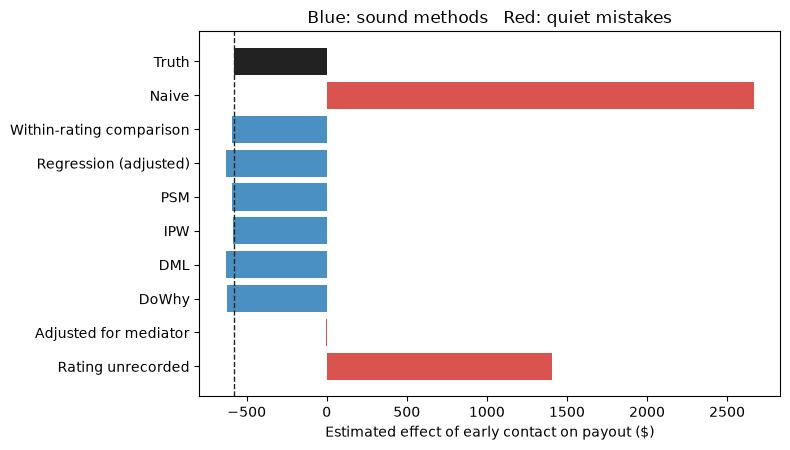

,Estimate
Truth,$-581
Naive,"$2,666"
Within-rating comparison,$-592
Regression (adjusted),$-628
PSM,$-594
IPW,$-586
DML,$-630
DoWhy,$-625
Adjusted for mediator,$-3
Rating unrecorded,"$1,409"


In [ ]:
scores = {"Truth": TRUE_ATE, "Naive": naive, "Within-rating comparison": ate_strat,
          "Regression (adjusted)": coef_on_contact(good),
          "PSM": ate_psm, "IPW": ate_ipw, "DML": ate_dml, "DoWhy": est_reg.value,
          "Adjusted for mediator": with_mediator, "Rating unrecorded": no_rating}

fig, ax = plt.subplots(figsize=(8, 4.6))
names, vals = list(scores), list(scores.values())
bad = ("Naive", "Adjusted for mediator", "Rating unrecorded")
colors = ["#222" if n == "Truth" else "#d9534f" if n in bad else "#4a90c2" for n in names]
ax.barh(names[::-1], vals[::-1], color=colors[::-1])
ax.axvline(TRUE_ATE, color="#222", ls="--", lw=1)
ax.set_xlabel("Estimated effect of early contact on payout ($)")
ax.set_title("Blue: sound methods   Red: quiet mistakes")
plt.tight_layout(); plt.show()
pd.Series(scores).round(0).astype(int).map("${:,}".format).to_frame("Estimate")

Everything in blue lands near the true effect of about −$600. Everything in red is wrong, and **none of the red bars produced an error message.** Estimating is the easy part; the discipline is in the graph.

## Part 7: The doorway to rung 3

Rungs 1 and 2 are about **groups**: "among claims like these, how often...?" and "if we changed the policy for everyone, what happens on average?" Rung 3 is about **one specific case**.

Start with the smoking story, which is easy to feel:
- **Rung 1:** Smokers get lung cancer more often than non-smokers.
- **Rung 2:** If we got a population to stop smoking, how much would cancer rates fall?
- **Rung 3:** *This* woman smoked for 30 years and developed cancer. **Would she still have developed cancer if she had never smoked?**

The same shape in fraud:
- **Rung 1:** Claims with mismatched receipts are more often high risk.
- **Rung 2:** If we contacted every claimant early, what happens to payouts overall?
- **Rung 3:** *Claim C-1043* was not contacted and paid $40,000. **Would it have paid less if we had contacted the claimant early?**

**Why ask rung 3 questions?** Because they decide responsibility, explanations, and individual fairness: Was it the missing early contact that cost us? Is a denial justified? What would this person have to change to get a different outcome?

**How is rung 3 drawn?** It takes three moves, in words:
1. **Recall**: use what we observed about this specific claim to figure out what is going on *for it* (including hidden, claim-specific factors).
2. **Change**: make the one change ("it was contacted early").
3. **Replay**: run the claim's own mechanism forward again with the hidden factors kept the same.

The graph for this is a **twin network**: two copies of the graph, the actual world and the imagined world, sharing the same hidden factors. We only sketch this now. To do it properly we need *equations* for how each variable is produced (**structural causal models**), which is Module 13.

### How this connects to explainability (Module 13 preview)
- **SHAP and LIME** explain a model's predictions using *associations in the data*. They sit on **rung 1**: they tell you what the model *uses*, not what would happen if you *changed* something in the world.
- **Counterfactual explanations** ("approval would have happened if your income were $5,000 higher") are **rung 3** statements.
- **Algorithmic recourse** ("what can this person actually do to change the outcome?") is a **rung 2** question: it asks about actions, and actions need a causal graph.

## Wrap-up

**The takeaways**
1. The ladder sorts questions by what you need to answer them: **data** (seeing), **data + graph** (doing), **data + graph + equations** (imagining).
2. **Seeing is not doing.** 0.0454 versus 0.1532 for receipts and fraud, and about +$2,700 versus −$600 for early contact and payout.
3. Fixing a clue does not fix its cause, and it can destroy the clue.
4. `do(X)` is **graph surgery**: cut the arrows into X. Do-calculus rewrites a `do` question into a seeing question when the graph allows it.
5. **Identification** (logic, uses the graph) comes before **estimation** (statistics, uses the data).
6. Within-group comparison, PSM, IPW and DML are different ways to carry out the same adjustment. DoWhy chains model, identify, estimate, refute.
7. Adjust for confounders; never for mediators; and no method can recover a confounder you did not measure.

**Coming up:** Module 13 climbs to rung 3 with structural causal models, counterfactual explanations, and algorithmic recourse, and examines why SHAP and LIME stop at rung 1.

## Reflection (activity)
Start a new text cell and write about **100–150 words** responding to this prompt:

*Pick a decision from your own work or daily life where someone said "the data shows X goes with Y, so let's change X." Which rung is that claim on, and which rung does the decision actually need? Name one possible confounder or mediator that could make the "obvious" action fail, and describe what you would need (a graph, an experiment, or other evidence) to trust the answer.*